$$
p= q B \rho
$$ 

In [327]:
import numpy as np 


def circumference(radius = 1000) :
    return 2 * np.pi * radius 

def momentum_from_energy(energy, mass) :
    return np.sqrt(energy**2 - mass**2)

def revolution_period(circumference, beta) : 
    return circumference/(beta*c)

def revolution_frequency(circumference, beta) :
    return 1/revolution_period(circumference, beta)

def field_from_momentum_radius(momentum, charge, radius) : 
    return momentum/(q*radius)/c

def radius_from_momentum_field(momentum, charge, field) :
    return momentum/(q*field)/c

def gamma_from_energy(energy, mass) :
    return energy/mass 

def beta_from_gamma(gamma) :
    return np.sqrt(1-1/gamma**2)

q = 1
c = 299792458
R0 = 1000
mass = 511009.95 # electron mass 

E0 = 1e9 # 10 GeV
C0 = circumference(radius=R)
p0 = momentum_from_energy(E0,mass)
gamma0 = gamma_from_energy(E0,mass)
beta0 = beta_from_gamma(gamma0)
T0 = revolution_period(C0, beta0)
f0 = revolution_frequency(C0, beta0)
B0 = field_from_momentum_radius(p0, q, R)
print('circumference',C0)
print('gamma',gamma0)
print('beta',beta0)
print('revolution_period',T0)
print('revolution_freq',f0)
print('p0',p0)
print('B0',B0)

def voltage(voltage_amplitude=1e6, phi=np.pi/4.0) :
    return q*voltage_amplitude*np.sin(phi)

def turn_update(mass, E_s, E, v_amp=100e6, phi_s=np.pi/4.0, phi = np.pi/4.0, h=5000) : 
    V_s = voltage(v_amp, phi_s)
    V = voltage(v_amp, phi) 
    
    E_s += V_s 
    E  += V
    
    p_s = momentum_from_energy(E_s, mass)
    p   = momentum_from_energy(E, mass)

    B_s = field_from_momentum_radius(p_s, q, R0)
    R   = radius_from_momentum_field(p, q, B_s)
    C   = circumference(R)

    gamma_s = gamma_from_energy(E_s, mass)
    gamma   = gamma_from_energy(E, mass)

    beta_s = beta_from_gamma(gamma_s)
    beta   = beta_from_gamma(gamma)

    T = revolution_period(C,beta)
    phi += 2*np.pi*(T-T0)*f0*h
    
    
    #print(B_s)
    #print(E_s, E)
    #print(p_s,p)
    #print(gamma_s, gamma)
    #print(beta_s, beta)
    #print(R0, R)
    #print(T0,T, T-T0)
    #print(dphi)

    return E_s, E, phi

circumference 6283.185307179586
gamma 1956.9090582287097
beta 0.999999869434407
revolution_period 2.0958452955969653e-05
revolution_freq 47713.44536263433
p0 999999869.434407
B0 0.0033356405164615814


In [328]:
import matplotlib.pyplot as plt

def plot(E0, phi_s = np.pi/2.0, phi=np.pi/2.0+0.1) :
    E_s = E0
    E = E0
    
    E_s_array = []
    E_array = []
    phi_array = [] 
    for i in range(0,100,1) :
        E_s, E, phi = turn_update(mass, E0, E0, v_amp=1e6, phi_s=phi_s, phi=phi, h=4000)
        
        E_s_array.append(E_s)
        E_array.append(E)
        phi_array.append(phi)
    
    plt.plot(phi_array, np.array(E_array))
    plt.xlabel("phase")
    plt.ylabel("energy")
        

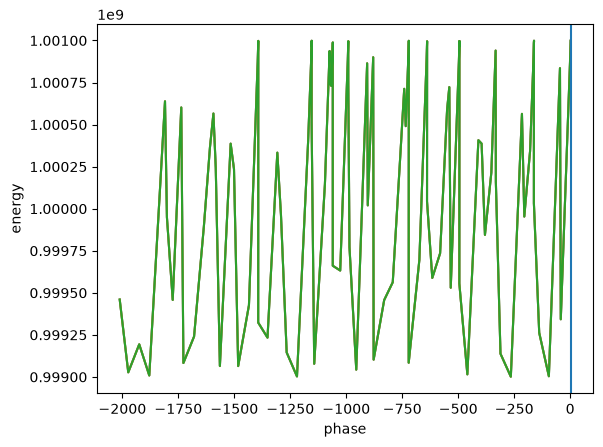

In [330]:
plot(E0,np.pi/2+0.2, np.pi/2+0.05)
plot(E0,np.pi/2+0.2, np.pi/2+0.05)
plot(E0,np.pi/2+0.2, np.pi/2+0.05)
plt.axvline(np.pi/2)